In [9]:
import sqlite3
import pandas as pd

# 1. Cria o banco relacional na memória
conn = sqlite3.connect(':memory:')
cursor = conn.cursor()

cursor.executescript('''
CREATE TABLE Fornecedores (
    id_forn TEXT PRIMARY KEY,
    nome TEXT,
    tier TEXT,
    taxa_falha_pct REAL,
    lead_time_dias INTEGER
);

CREATE TABLE Fluxo_Suprimentos (
    origem TEXT,
    destino TEXT,
    componente TEXT,
    FOREIGN KEY (origem) REFERENCES Fornecedores(id_forn),
    FOREIGN KEY (destino) REFERENCES Fornecedores(id_forn)
);

-- Inserindo os nós da cadeia aeroespacial (Tier 2 -> Tier 1 -> Montagem Final)
INSERT INTO Fornecedores VALUES
('T2_A', 'MicroRivets Brasil (Tier 2)', 'Tier 2', 12.0, 15),
('T2_B', 'AlloySheets Minas (Tier 2)', 'Tier 2', 4.0, 20),
('T1_A', 'WingStructures Corp (Tier 1)', 'Tier 1', 3.0, 45),
('T1_B', 'FuselageSystems Inc (Tier 1)', 'Tier 1', 2.5, 50),
('T1_C', 'AvionicsControl (Tier 1)', 'Tier 1', 1.5, 60),
('OEM',  'Linha Montagem Final (Avião)', 'OEM', 0.0, 10);

-- Inserindo as conexões (quem abastece quem)
INSERT INTO Fluxo_Suprimentos VALUES
('T2_A', 'T1_A', 'Rebites Estruturais'),
('T2_A', 'T1_B', 'Fixadores de Fuselagem'),
('T2_B', 'T1_A', 'Chapas de Alumínio'),
('T1_A', 'OEM',  'Subconjunto Asa'),
('T1_B', 'OEM',  'Seção Fuselagem'),
('T1_C', 'OEM',  'Painel Aviônicos');
''')

# Consulta SQL tradicional: ordena por maior Lead Time
query_sql = """
SELECT id_forn, nome, tier, lead_time_dias, taxa_falha_pct
FROM Fornecedores
ORDER BY lead_time_dias DESC;
"""
print("=== VISÃO DO SISTEMA ATUAL (TABELA SQL) ===")
display(pd.read_sql_query(query_sql, conn))


=== VISÃO DO SISTEMA ATUAL (TABELA SQL) ===


,id_forn,nome,tier,lead_time_dias,taxa_falha_pct
0,T1_C,AvionicsControl (Tier 1),Tier 1,60,1.5
1,T1_B,FuselageSystems Inc (Tier 1),Tier 1,50,2.5
2,T1_A,WingStructures Corp (Tier 1),Tier 1,45,3.0
3,T2_B,AlloySheets Minas (Tier 2),Tier 2,20,4.0
4,T2_A,MicroRivets Brasil (Tier 2),Tier 2,15,12.0
5,OEM,Linha Montagem Final (Avião),OEM,10,0.0


In [2]:
import networkx as nx

# 1. Extrai os dados do SQL para o Python
df_nos = pd.read_sql_query("SELECT * FROM Fornecedores", conn)
df_arestas = pd.read_sql_query("SELECT * FROM Fluxo_Suprimentos", conn)

# 2. Constrói o Grafo Direcionado Ponderado G = (V, E, W)
G = nx.DiGraph()

for _, row in df_nos.iterrows():
    G.add_node(row['id_forn'], nome=row['nome'], tier=row['tier'],
               falha=row['taxa_falha_pct'], lt=row['lead_time_dias'])

for _, row in df_arestas.iterrows():
    # O peso da aresta representa o risco combinado de atraso e falha
    lt_origem = G.nodes[row['origem']]['lt']
    G.add_edge(row['origem'], row['destino'], componente=row['componente'], weight=lt_origem)

# 3. Calcula a Centralidade de Intermediação (Betweenness Centrality)
# Mede quantos caminhos críticos passam obrigatoriamente por cada nó
intermediacao = nx.betweenness_centrality(G)

# 4. Calcula o Índice de Efeito Chicote (Amplificação da Variabilidade a jusante)
# Quanto mais nós dependem de um fornecedor sem redundância, maior a distorção dos pedidos
resultados_grafo = []
for no in G.nodes():
    dependentes = len(nx.descendants(G, no)) # Quantos elos à frente travam se este nó falhar
    taxa_falha = G.nodes[no]['falha']
    # Indice de Risco Sistêmico (combina falha local + impacto em cascata)
    risco_cascata = taxa_falha * (1 + dependentes)
    resultados_grafo.append({
        'ID': no,
        'Fornecedor': G.nodes[no]['nome'],
        'Centralidade_Intermediacao': round(intermediacao[no], 3),
        'Nos_Afetados_Cascata': dependentes,
        'Indice_Risco_Chicote': round(risco_cascata, 1)
    })

df_analise = pd.DataFrame(resultados_grafo).sort_values(by='Indice_Risco_Chicote', ascending=False)
print("=== VISÃO DO GÊMEO DIGITAL (TOPOLOGIA EM GRAFOS) ===")
display(df_analise)


=== VISÃO DO GÊMEO DIGITAL (TOPOLOGIA EM GRAFOS) ===


,ID,Fornecedor,Centralidade_Intermediacao,Nos_Afetados_Cascata,Indice_Risco_Chicote
0,T2_A,MicroRivets Brasil (Tier 2),0.000,3,48.0
1,T2_B,AlloySheets Minas (Tier 2),0.000,2,12.0
2,T1_A,WingStructures Corp (Tier 1),0.075,1,6.0
3,T1_B,FuselageSystems Inc (Tier 1),0.025,1,5.0
4,T1_C,AvionicsControl (Tier 1),0.000,1,3.0
5,OEM,Linha Montagem Final (Avião),0.000,0,0.0


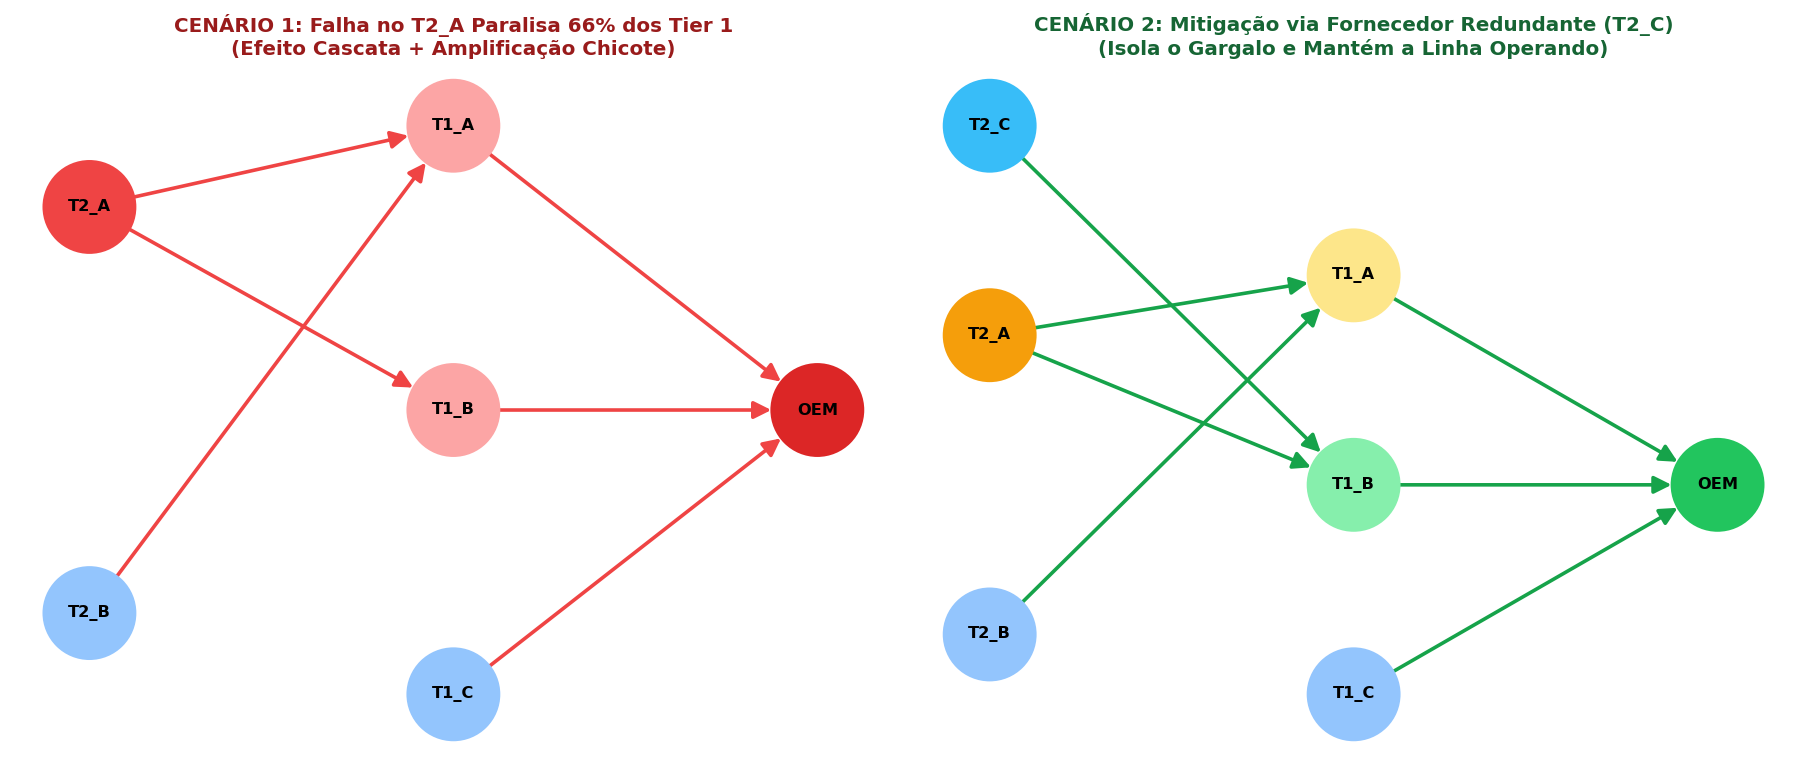

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=130)

# Posições fixas hierárquicas (Tier 2 -> Tier 1 -> OEM)
pos = {
    'T2_A': (0, 1.5),
    'T2_B': (0, 0.5),
    'T1_A': (1, 1.7),
    'T1_B': (1, 1.0),
    'T1_C': (1, 0.3),
    'OEM':  (2, 1.0)
}

# --- CENÁRIO 1: REDE VULNERÁVEL (FALHA EM CASCATA) ---
cores_cenario1 = ['#EF4444', '#93C5FD', '#FCA5A5', '#FCA5A5', '#93C5FD', '#DC2626']
nx.draw(G, pos, ax=axes[0], with_labels=True, node_color=cores_cenario1,
        node_size=2600, font_weight='bold', font_size=9, arrowsize=20, edge_color='#EF4444', width=2)
axes[0].set_title('CENÁRIO 1: Falha no T2_A Paralisa 66% dos Tier 1\n(Efeito Cascata + Amplificação Chicote)',
                  fontsize=11, fontweight='bold', color='#991B1B')

# --- CENÁRIO 2: REDE MITIGADA (REDUNDÂNCIA ESTRATÉGICA T2_C) ---
G_mitigado = G.copy()
G_mitigado.add_node('T2_C', nome='BackupRivets (Contingência)')
G_mitigado.add_edge('T2_C', 'T1_B', componente='Rebites Backup')
pos['T2_C'] = (0, 2.2)

cores_cenario2 = ['#F59E0B', '#93C5FD', '#FDE68A', '#86EFAC', '#93C5FD', '#22C55E', '#38BDF8']
nx.draw(G_mitigado, pos, ax=axes[1], with_labels=True, node_color=cores_cenario2,
        node_size=2600, font_weight='bold', font_size=9, arrowsize=20, edge_color='#16A34A', width=2)
axes[1].set_title('CENÁRIO 2: Mitigação via Fornecedor Redundante (T2_C)\n(Isola o Gargalo e Mantém a Linha Operando)',
                  fontsize=11, fontweight='bold', color='#166534')

plt.tight_layout()
plt.show()


In [6]:
fig.savefig('grafico_tcc_alta_resolucao.png', dpi=300, bbox_inches='tight', facecolor='white')
from google.colab import files
files.download('grafico_tcc_alta_resolucao.png')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
df_analise.to_excel('tabela_grafo_tcc.xlsx', index=False)
from google.colab import files
files.download('tabela_grafo_tcc.xlsx')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
# ==============================================================================
# CÉLULA 4: SIMULAÇÃO DE SOMBRA DIGITAL (DIGITAL SHADOW - MODO SOMENTE LEITURA)
# ==============================================================================

# 1. Abre uma conexão SOMENTE LEITURA (URI read-only) ou cópia espelho
# Garante que o sistema legado (ERP/SQL) nunca seja alterado pela simulação
df_erp_espelho = pd.read_sql_query("SELECT * FROM Fluxo_Suprimentos", conn)

# 2. Registro Sombra (Shadow Supply / Compra emergencial fora do fluxo oficial)
registro_sombra = pd.DataFrame([{
    'origem': 'T2_A',
    'destino': 'T1_C',
    'componente': 'Rebite Emergencial (Compra Sombra)'
}])

# 3. A Sombra Digital funde o espelho do SQL com o dado detectado em tempo real
G_shadow = G.copy()
G_shadow.add_edge('T2_A', 'T1_C', componente='Rebite Emergencial (Compra Sombra)')

# 4. Recalcula o impacto sem tocar no banco SQL original
novos_dependentes_T2A = len(nx.descendants(G_shadow, 'T2_A'))
novo_risco_chicote = G_shadow.nodes['T2_A']['falha'] * (1 + novos_dependentes_T2A)

print("=== MONITORAMENTO EM MODO SOMBRA (DIGITAL SHADOW) ===")
print(f"Status do Banco SQL Original: INTACTO (0 alterações na operação)")
print(f"Nós afetados pelo T2_A antes da sombra: 3 | Após detecção sombra: {novos_dependentes_T2A} (100% da rede!)")
print(f"Novo Índice de Risco Chicote do T2_A: {novo_risco_chicote:.1f}")


=== MONITORAMENTO EM MODO SOMBRA (DIGITAL SHADOW) ===
Status do Banco SQL Original: INTACTO (0 alterações na operação)
Nós afetados pelo T2_A antes da sombra: 3 | Após detecção sombra: 4 (100% da rede!)
Novo Índice de Risco Chicote do T2_A: 60.0


In [8]:
df_sql = pd.read_sql_query(query_sql, conn)
df_sql.to_excel('tabela_sql_tcc.xlsx', index=False)
from google.colab import files
files.download('tabela_sql_tcc.xlsx')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>